# 旅行商问题：寻找总距离最小的闭合回路

## 这一章讲什么

这一章要解决的问题是，每个城市都走一遍，最后回到出发的地方，而且路要最短。

- 巡回路线交给 `add_circuit()` 来做
- 总距离用 `model.minimize()` 压到最小
- 目标函数一路如何改善，用回调记录下来
- 再补几条约束，连必须经过线段这类变形的 TSP 也能解出来

## 旅行商问题(TSP)

每个城市各去一次，再回到出发点，求路程最短的那个顺序，这就是 TSP。

它属于 NP 困难问题，由于城市数 $N$ 一增加，可能的路径数就按 $(N-1)!/2$ 的速度增长，因此规模稍大就无法再使用穷举法求解了。

| 城市数 | 路径数(大约) |
|---|---|
| 10 | 18 万 |
| 15 | 4 亿 |
| 20 | 1.2 万亿 |

当问题的规模达到穷举法无法应付时，就只能使用求解器了。而在 CP-SAT 中，把“每个城市出去 1 条、进来 1 条”的回路约束与距离最小化摆在一起，模型就成了。

In [1]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import spatial
from matplotlib.collections import LineCollection
from ortools.sat.python import cp_model

## 测试数据

随机撒 100 个点，把两两之间的距离全部算出来，得到一张距离矩阵。CP-SAT 只处理整数，因此距离先乘 1000，转成整数再往下走。

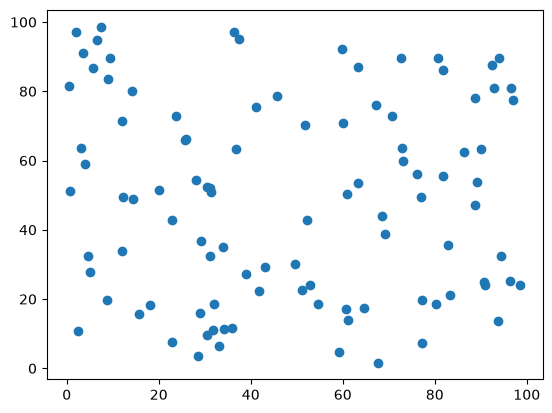

In [2]:
n = 100
np.random.seed(42)
points = np.random.uniform(0, 100, size=(n, 2))

# 距离矩阵（乘 1000 变成整数）
dist_matrix = (spatial.distance.squareform(spatial.distance.pdist(points)) * 1000).astype(np.int32)

fig, ax = plt.subplots()
ax.scatter(points[:, 0], points[:, 1]);

## 记录改善的历史

继承 `CpSolverSolutionCallback`，就可以挂一个函数上去，每次搜到新解它都会被调用一次。这里用它记下目标函数(总距离)是如何逐步降低的。

In [3]:
class ObjectiveTracker(cp_model.CpSolverSolutionCallback):
    """记录搜索过程中找到的目标函数值"""

    def __init__(self):
        super().__init__()
        self.history = []

    def on_solution_callback(self):
        self.history.append(self.objective_value)

## 求解

`solve_points_tsp()` 走的是这五个步骤。

1. 从距离矩阵做出一张 `(i, j) → 距离` 的字典 `edges`，`i == j` 那几条不算
2. 每条边配一个布尔变量，为真就表示这条路被选中
3. `add_circuit()` 逼出一条闭合回路
4. `LinearExpr.weighted_sum()` 把总距离算出来，再交给 `model.minimize()` 去压
5. 从选中的边里，把路径的坐标一个个取出

只要超过 `max_time` 就停下，这时候拿到的解是可行的，但未必最优，检查状态是 `OPTIMAL` 还是 `FEASIBLE`，就知道属于哪一种情况。

In [4]:
def solve_points_tsp(points, dist_matrix, log_history=False, max_time=10):
    """求绕遍点集的最短巡回路线"""
    edges = {}
    for (i, j), d in np.ndenumerate(dist_matrix):
        if i != j:
            edges[i, j] = int(d)

    model = cp_model.CpModel()
    variables = {key: model.new_bool_var(f"e{i}") for i, key in enumerate(edges)}
    model.add_circuit([(s, e, v) for (s, e), v in variables.items()])

    # 让经过的边的距离合计最小
    length = cp_model.LinearExpr.weighted_sum(list(variables.values()), list(edges.values()))
    model.minimize(length)

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = max_time
    if log_history:
        callback = ObjectiveTracker()
        status = solver.solve(model, callback)
        print("status:", solver.status_name(status))
        print("距离的变化:", callback.history)
    else:
        status = solver.solve(model)
        print("status:", solver.status_name(status))

    selected = points[np.array([key for key, v in variables.items() if solver.value(v)])]
    return selected

拿 100 个点来解，把选中的边一条条连成线，画出完整的路径。

status: OPTIMAL
距离的变化: [5094854.0, 1132119.0, 779053.0, 777936.0, 775700.0, 774583.0, 772782.0, 755075.0, 754851.0, 746285.0, 745684.0]


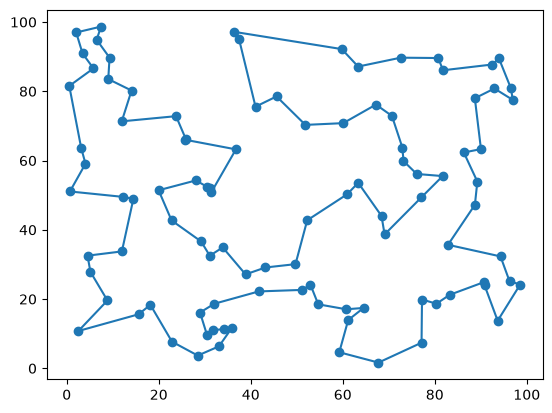

In [5]:
selected_edges = solve_points_tsp(points, dist_matrix, log_history=True)
fig, ax = plt.subplots()
ax.scatter(points[:, 0], points[:, 1])
ax.add_collection(LineCollection(selected_edges));

## 线段的 TSP

下面换一种情形：巡回的对象不是点，而是线段，盘上摆 50 条线段，再加一条规矩，即每条线段都得从某一端进、从另一端出。

线段得先造出来，下面先看怎么造。

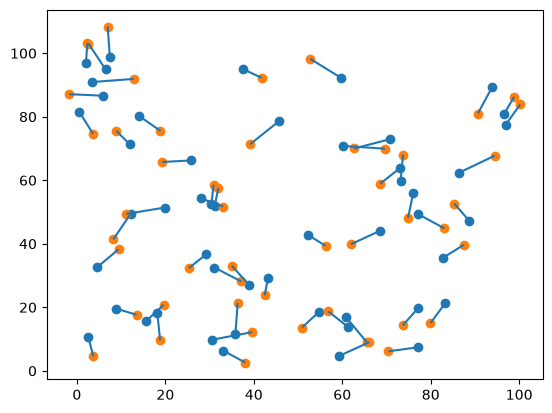

In [6]:
n = 50
np.random.seed(42)
start_points = np.random.uniform(0, 100, size=(n, 2))
length = np.random.uniform(5, 10, size=n)
angle = np.random.uniform(0, 2 * np.pi, size=n)
end_points = start_points + np.c_[length * np.cos(angle), length * np.sin(angle)]
segments = np.column_stack([start_points, end_points])
points = segments.reshape(-1, 2)

fig, ax = plt.subplots()
ax.scatter(start_points[:, 0], start_points[:, 1])
ax.scatter(end_points[:, 0], end_points[:, 1])
ax.add_collection(LineCollection(segments.reshape(-1, 2, 2)))

### 约束太弱，就不会经过线段

先只做一件事：把同一条线段两端的距离设成 0。线段上跑一趟不花钱，可这并不保证所有线段都被使用，因为绕开那些成本为 0 的路、改走更短的近道，总距离反而更小。

下图里红线是原来的线段，黑线是选中的路线。读者可以自己看看有没有哪条线段实际上没有被走到。

status: OPTIMAL
距离的变化: [5215210.0, 5208664.0, 947648.0, 536334.0, 461284.0, 429924.0, 428821.0, 427685.0, 425074.0, 424315.0, 423622.0]


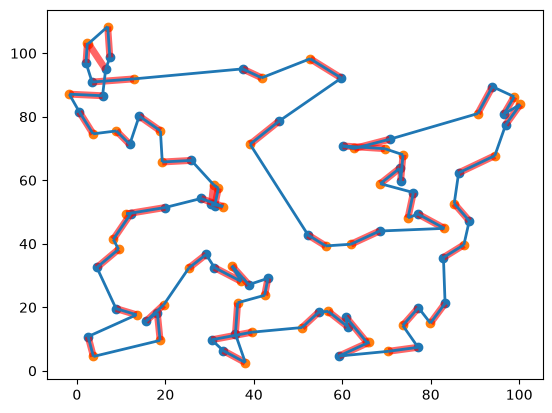

In [7]:
dist_matrix = (spatial.distance.squareform(spatial.distance.pdist(segments.reshape(-1, 2))) * 1000).astype(np.int32)
start_index = np.arange(0, n * 2, 2)
end_index = start_index + 1
# 把线段两端的距离设为 0
dist_matrix[start_index, end_index] = 0
dist_matrix[end_index, start_index] = 0

selected_edges = solve_points_tsp(points, dist_matrix, log_history=True)
fig, ax = plt.subplots()
ax.scatter(start_points[:, 0], start_points[:, 1])
ax.scatter(end_points[:, 0], end_points[:, 1])
ax.add_collection(LineCollection(segments.reshape(-1, 2, 2), linewidth=5, color='red', alpha=0.6))
ax.add_collection(LineCollection(selected_edges, linewidth=2))

### 用约束加上“必须经过”

对线段 `(s, e)`，用 `add_exactly_one()` 约束一下：`s → e` 与 `e → s` 里必须走一条。这样绕出来的路线，每条线段都会跑过。

In [8]:
def solve_segments_tsp(points, dist_matrix, log_history=False, max_time=10):
    """求经过所有线段的最短路线"""
    edges = {}
    for (i, j), d in np.ndenumerate(dist_matrix):
        if i != j:
            edges[i, j] = int(d)

    n = dist_matrix.shape[0]
    start_index = np.arange(0, n, 2)
    end_index = start_index + 1

    model = cp_model.CpModel()
    variables = {key: model.new_bool_var(f"e{i}") for i, key in enumerate(edges)}
    model.add_circuit([(s, e, v) for (s, e), v in variables.items()])

    # 每条线段必须经过其中一个方向
    for s, e in zip(start_index, end_index):
        model.add_exactly_one([variables[s, e], variables[e, s]])

    length = cp_model.LinearExpr.weighted_sum(list(variables.values()), list(edges.values()))
    model.minimize(length)

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = max_time
    if log_history:
        callback = ObjectiveTracker()
        status = solver.solve(model, callback)
        print("status:", solver.status_name(status))
        print("距离的变化:", callback.history)
    else:
        status = solver.solve(model)
        print("status:", solver.status_name(status))

    selected = points[np.array([key for key, v in variables.items() if solver.value(v)])]
    return selected

这么一来，跑遍全部线段的路线就到手了，问题也就解完了。

status: OPTIMAL
距离的变化: [1358864.0, 1129401.0, 823853.0, 711604.0, 630001.0, 556269.0, 544769.0, 540940.0, 538884.0, 535907.0, 532078.0, 524710.0, 498004.0, 493894.0, 489224.0, 456436.0, 455037.0, 438037.0, 437024.0, 436133.0, 434591.0, 429840.0, 429027.0, 425941.0]


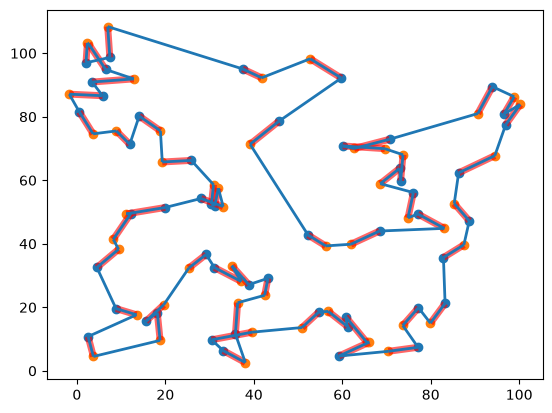

In [9]:
selected_edges = solve_segments_tsp(points, dist_matrix, log_history=True)
fig, ax = plt.subplots()
ax.scatter(start_points[:, 0], start_points[:, 1])
ax.scatter(end_points[:, 0], end_points[:, 1])
ax.add_collection(LineCollection(segments.reshape(-1, 2, 2), linewidth=5, color='red', alpha=0.6))
ax.add_collection(LineCollection(selected_edges, linewidth=2))

## 小结

- TSP 落到代码上只有两件事：`add_circuit()` 加上 `minimize(距离合计)`
- 距离得取整数，例如把距离乘 1000 就是常用办法，因为 CP-SAT 碰不了小数
- 想知道解如何逐步变好，就继承 `CpSolverSolutionCallback`
- `max_time_in_seconds` 可以限时，时间到点拿到的解是 `FEASIBLE`，其最优性没有保证
- “必须经过”这类条件，在边的变量上补个 `add_exactly_one` 之类的约束就写出来了
- 约束写弱了，就得不到想要的路线(线段那个例子)，条件必须明明白白写出来